## Pegasus Evaluation: Evidence per Service

Section B.2. Setup, methods and metrics: `2a_base_case.ipynb`; parameters: `pegasus/evaluation_setup.py`.

In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
import pandas as pd
from pegasus.figures import math_label, sweep_table, time_table
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))
# the base case of B.1 that this notebook builds on: read from statics/evaluation_cache/ (written by the first
# notebook that needs it), or computed here if the cache is missing or stale (b1_base)
globals().update(b1_base(data_source))
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {n_train} training configurations per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

base case of B.1 loaded from statics/evaluation_cache/b1_real+b1+b1u-max3_884f34446e6214f4.joblib
real data, 3 seeds: chain detector -> transformer -> compressor, per seed 25 training configurations per service and 120 held-out configurations, poisson arrivals at one rate per configuration (1.58 to 65/s)


### B.2 Varying Evidence per Service

The training runs of a chain grow one service at a time (`evidence_levels`, then all runs); after every step the models
are refit and every method is evaluated on the held-out runs of the chain.

- **Real:** `EVIDENCE_CHAIN` (`b1-vision-3-single`: denoiser → object detector → face detector → compressor). Every
  service trains on its benchmark and its runs in the other chains of `b1/` (`BENCHMARK_AND_CHAINS`).
- **Synthetic:** the chain of B.1, up to 200 training configurations per service.
- **Methods:** as in B.1, without DNN Sum and Pegasus SNC.
- **Schedules** (`pegasus/evidence.py`): *all services together* (in turn), *most uncertain first* (largest cost of
  uncertainty, `uncertainty_cost`: median increase of the node bound from the predicted to the pessimistic mean), and
  *least uncertain first* (control).
- **Service models and Pegasus Node** (all services growing together, `uncertainty_levels`): per service, the error of
  the predicted mean execution time against the measured mean of the held-out run and the margin of the pessimistic
  mean; and the tightness of Pegasus Node, also with the predicted means in place of the pessimistic ones.

Figures: `figures/tsc/b2_evidence_<data source>_{schedules,uncertainty,tightness}`.

In [2]:
# B.2: the chain of B.2 while the training runs of its services grow one service at a time, under every schedule (pegasus/evidence.py)
from pegasus.evidence import (ALL_TOGETHER, COLORS as SCHEDULE_COLORS, MOST_UNCERTAIN, SCHEDULES, STYLES as SCHEDULE_STYLES, incremental_training,
                              schedule_figure)
from pegasus.figures import METHOD_STYLES

METHOD_COLORS.update(SCHEDULE_COLORS)   # sweep_line draws a line by its name
METHOD_STYLES.update(SCHEDULE_STYLES)
evidence_levels = [3, 10, 50]                 # training runs (configurations) per service at which a service stops; then all of them
calibration_share = n_calibration / n_train   # share of its runs that Conformal sets aside for calibration, as in B.1


def compute():
    evidence = {}         # (schedule, seed) -> per step: (runs per service, name -> (group, latency per held-out configuration),
                          #                               name -> (training time, evaluation time) in s, the service that moves up next)
    evidence_truth = {}   # seed -> (measured quantile, lower edge of its confidence interval) per held-out configuration
    with warnings.catch_warnings():
        # with few training runs the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for s in seeds:
            data = evidence_data(s)
            assert_unseen(data)
            evidence_truth[s] = (data.measured, data.measured_low)
            for schedule in SCHEDULES:
                evidence[(schedule, s)] = incremental_training(data, schedule, evidence_levels, alpha, confidence, calibration_share,
                                                               model_seed=seed + s, leave_out=only_base_case + (PROPOSED_SNC,))
    return dict(evidence=evidence, evidence_truth=evidence_truth, evidence_path=data.path)


globals().update(cached("b2_evidence", data_source, compute, inputs=dict(levels=evidence_levels, calibration_share=calibration_share)))
n_steps = len(evidence[(ALL_TOGETHER, seeds[0])])
print(f"{len(SCHEDULES)} schedules of {n_steps} training states each evaluated for {len(seeds)} seeds on {' -> '.join(evidence_path)}, "
      f"{len(evidence_truth[seeds[0]][0])} held-out configurations.")

b2_evidence: results loaded from statics/evaluation_cache/b2_evidence_real+b1+b1u-max3_70049e932078bb04.joblib
3 schedules of 13 training states each evaluated for 3 seeds on denoiser -> detector -> faces -> compressor, 107 held-out configurations.


In [3]:
# B.2: the service models and the bound of Pegasus Node against the training runs per service, on a finer grid of runs than
# evidence_levels, all services growing together. A service model is trained on the runs of its service alone, so its accuracy
# depends neither on the runs of the other services nor on the schedule: one fit per number of runs suffices
from pegasus.bounds import martingale_closed_form_node_bounds
from pegasus.evaluation import pegasus_bound
from pegasus.evidence import service_levels, training_prefix, uncertainty_cost
from pegasus.real_data import arrival_rates, chain_run_workers, chain_runs, combined_chain, path_hop_overheads, pipeline_steps
from pegasus.service_gp import execution_time_belief, run_statistics_belief

uncertainty_levels = [3, 5, 10, 20, 50, 100, 200]   # training runs per service at which its model is fitted; then all of them


def held_out_execution_means(data) -> np.ndarray:
    """(held-out runs, services): the measured mean execution time (s) of every service in every held-out run, the ground truth
    of the predicted mean: the mean processing time of the run plus the hop overhead of the service's position, as in the
    training targets. The runs in the order of real_chain_data: the unthrottled runs of the chain, then those of its twin with at
    most k workers per service (combined_chain)."""
    experiment = configure(data_source)["evidence_options"](seeds[0])["experiment"]
    chain, twin, k = combined_chain(experiment) or (experiment, None, None)
    means, rates = [], []
    for part, max_workers in ((chain, None), (twin, k)) if twin else ((chain, None),):
        runs = chain_runs(part, unthrottled_runs(part))
        if max_workers is not None:
            runs = [run for run, workers in zip(runs, chain_run_workers(part, runs)) if workers.max() <= max_workers]
        hop = path_hop_overheads(part)
        for run in runs:
            run_steps = pipeline_steps(part, run)
            means.append([run_steps.loc[run_steps["node"] == node, "processing_s"].mean() + hop[k_] for k_, node in enumerate(data.path)])
        rates.append(arrival_rates(part).loc[runs].to_numpy())
    assert np.allclose(np.concatenate(rates), data.workload["rate"]), "the measured runs are not the held-out runs in their order"
    return np.array(means)


def compute():
    # seed -> service -> array (levels, 6), every value but the runs a median over the held-out configurations: training runs,
    # uncertainty margin of the mean (m-bar / m - 1), uncertainty cost (s), predicted mean execution time m (s), node bound with m (s),
    # error of m against the measured mean, |m - measured| / measured
    uncertainty = {}
    chain_bound = {}   # seed -> end-to-end bound of the chain with the predicted means and all runs of every service (s), the reference
                       #         against which the cost of the uncertainty of a service is read
    chain_pegasus = {}   # seed -> array (levels, 7): training runs per service (a service with fewer runs holds all of them), the
                         #         end-to-end bound of Pegasus Node and that with the predicted means (s), the tightness of both (bound /
                         #         measured quantile), each the median over the held-out configurations, and the coverage of both
    with warnings.catch_warnings():
        # with few training runs the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for s in seeds:
            data = evidence_data(s)
            measured_means = held_out_execution_means(data)
            steps = service_levels(data, uncertainty_levels)
            belief_of = run_statistics_belief if data.y_train_spread is not None else execution_time_belief
            x_test = model_inputs(data.x_test, data.workers_column)   # the models receive no number of workers
            rows = {service: [] for service in data.path}
            chain_rows = []
            # one fit of all services per level; a service that already holds all its runs keeps them and is not recorded again
            n_levels = max(len(n) for n in steps.values())
            for j in range(n_levels):
                n = {service: steps[service][min(j, len(steps[service]) - 1)] for service in data.path}
                part = training_prefix(data, n)
                models = fit_services(part, part.x_train, part.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                cost = uncertainty_cost(part, models, alpha)
                # the median belief is the predicted mean; with the variance per item of the pessimistic belief, as in uncertainty_cost
                predicted = [(belief_of(models["gp"][service], configurations_of(x_test, service), 0.5)[0], var)
                             for service, (_, var) in zip(data.path, models["beliefs"])]
                bound = martingale_closed_form_node_bounds(predicted, epsilon=alpha / len(data.path), path_workers=path_workers(data), **data.workload)
                pessimistic_chain, predicted_chain = pegasus_bound(part, models, alpha), bound.sum(axis=0)   # per held-out configuration (s)
                chain_rows.append((max(n.values()), float(np.median(pessimistic_chain)), float(np.median(predicted_chain)),
                                   float(np.median(pessimistic_chain / data.measured)), float(np.median(predicted_chain / data.measured)),
                                   coverage(pessimistic_chain, data.measured_low), coverage(predicted_chain, data.measured_low)))
                if j == n_levels - 1:   # every service holds all its runs
                    chain_bound[s] = float(np.median(predicted_chain))
                for k, (service, (pessimistic, _)) in enumerate(zip(data.path, models["beliefs"])):
                    if j < len(steps[service]):
                        mean = predicted[k][0]
                        rows[service].append((n[service], float(np.median(pessimistic / mean - 1)), cost[service], float(np.median(mean)),
                                              float(np.median(bound[k])), float(np.median(np.abs(mean - measured_means[:, k]) / measured_means[:, k]))))
            uncertainty[s] = {service: np.array(r) for service, r in rows.items()}
            chain_pegasus[s] = np.array(chain_rows)
    return dict(uncertainty=uncertainty, chain_bound=chain_bound, chain_pegasus=chain_pegasus)


globals().update(cached("b2_uncertainty", data_source, compute, inputs=dict(levels=uncertainty_levels)))
print(f"service models fitted at {', '.join(f'{service} {len(uncertainty[seeds[0]][service])}' for service in evidence_path)} numbers of training runs "
      f"for {len(seeds)} seeds.")

b2_uncertainty: results loaded from statics/evaluation_cache/b2_uncertainty_real+b1+b1u-max3_ca4146ab9290074a.joblib
service models fitted at denoiser 7, detector 8, faces 8, compressor 8 numbers of training runs for 3 seeds.


B.2 evidence per service, real data: denoiser → detector → faces → compressor, Pegasus Node under every schedule, 107 held-out configurations, 3 seeds
save_figure: b2_evidence_real_schedules_tightness reaches beyond the figure by {'right': np.float64(0.02)} inches


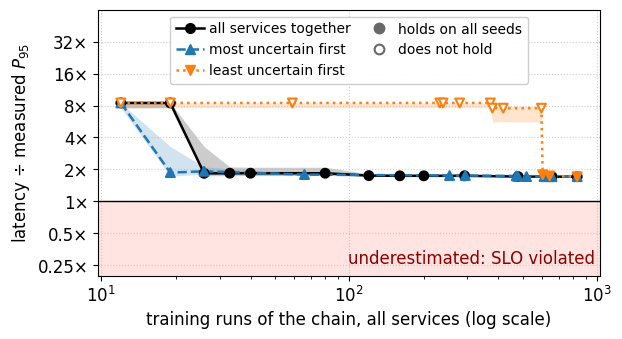

B.2 service models and Pegasus Node against the training runs per service, real data: denoiser → detector → faces → compressor, 107 held-out configurations, 3 seeds
legend_inside: the legend hides 2 points or bands at its best location (upper center)


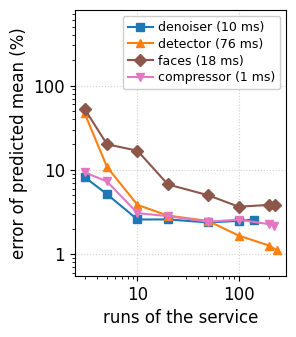

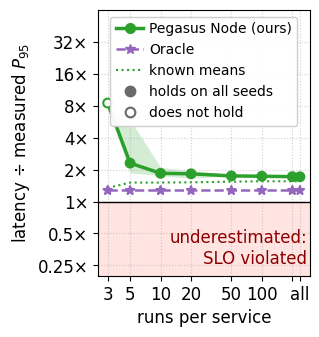

B.2 evidence per service, real data: denoiser → detector → faces → compressor, all services together, 107 held-out configurations, 3 seeds


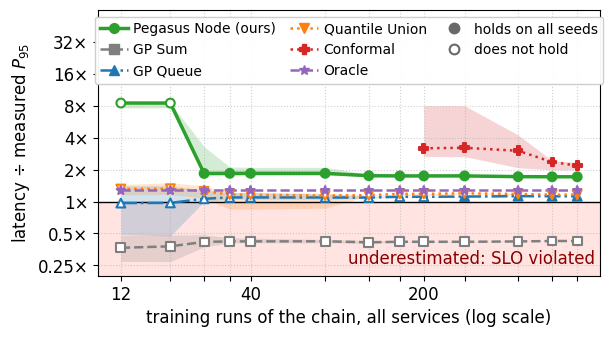

In [4]:
# B.2: coverage and tightness per training state; the ground truth is the same at every state
from pegasus.evaluation import uncertainty_figure

training_unit = "training runs" if data_source == "real" else "training configurations"
steps = list(range(n_steps))
per_step = lambda schedule: {(k, s): evidence[(schedule, s)][k][1] for k in steps for s in seeds}   # (step, seed) -> name -> (group, latency)
step_truth = {(k, s): evidence_truth[s] for k in steps for s in seeds}
runs_of = lambda schedule: np.array([[[evidence[(schedule, s)][k][0][node] for node in evidence_path] for s in seeds] for k in steps])   # (steps, seeds, services)
# total runs of the chain at every step, the median over the seeds (the same under every seed for ALL_TOGETHER)
evidence_totals = {schedule: np.median(runs_of(schedule).sum(axis=2), axis=1) for schedule in SCHEDULES}
schedule_statistics = {schedule: sweep_statistics(per_step(schedule), step_truth, steps, seeds, confidence)[PROPOSED] for schedule in SCHEDULES}
schedule_figure(evidence_totals, schedule_statistics,
                f"B.2 evidence per service, {data_source} data: {' → '.join(evidence_path)}, Pegasus Node under every schedule, "
                f"{len(evidence_truth[seeds[0]][0])} held-out configurations, {len(seeds)} seeds", p_label, name=f"b2_evidence_{data_source}_schedules")
# the Oracle uses no training data, so it is the same at every step; taken from the first step of every seed
oracle_bound = {s: float(np.median(evidence[(ALL_TOGETHER, s)][0][1]["Oracle"][1])) for s in seeds if "Oracle" in evidence[(ALL_TOGETHER, s)][0][1]}
# the Oracle per seed: its tightness (median over the held-out configurations) and its coverage, for the right figure
oracle_statistics = {s: (float(np.median(evidence[(ALL_TOGETHER, s)][0][1]["Oracle"][1] / evidence_truth[s][0])),
                         coverage(evidence[(ALL_TOGETHER, s)][0][1]["Oracle"][1], evidence_truth[s][1]))
                     for s in seeds if "Oracle" in evidence[(ALL_TOGETHER, s)][0][1]}
# how slow every service is: the median over the held-out runs of its measured mean execution time (s), for the legend
execution_times = dict(zip(evidence_path, np.median(held_out_execution_means(evidence_data(seeds[0])), axis=0))) if data_source == "real" else None
uncertainty_figure(uncertainty, chain_pegasus, evidence_path,
                   f"B.2 service models and Pegasus Node against the training runs per service, {data_source} data: {' → '.join(evidence_path)}, "
                   f"{len(evidence_truth[seeds[0]][0])} held-out configurations, {len(seeds)} seeds", confidence, name=f"b2_evidence_{data_source}_uncertainty",
                   oracle=oracle_statistics or None, level_label=p_label, execution_times=execution_times)

# every method under ALL_TOGETHER, whose totals are the same under every seed; a tick only where all services have the same number of runs
together = {(evidence_totals[ALL_TOGETHER][k], s): evidence[(ALL_TOGETHER, s)][k][1] for k in steps for s in seeds}
together_truth = {(evidence_totals[ALL_TOGETHER][k], s): evidence_truth[s] for k in steps for s in seeds}
together_totals = list(evidence_totals[ALL_TOGETHER])
evidence_statistics = sweep_statistics(together, together_truth, together_totals, seeds, confidence)   # name -> coverage, tightness, holds, computed
equal = runs_of(ALL_TOGETHER)[:, 0, :]
tightness_sweep_figure(together_totals, evidence_statistics, f"{training_unit} of the chain, all services (log scale)",
                       f"B.2 evidence per service, {data_source} data: {' → '.join(evidence_path)}, all services together, "
                       f"{len(evidence_truth[seeds[0]][0])} held-out configurations, {len(seeds)} seeds", p_label,
                       tick_labels=[f"{total:g}" if (row == row[0]).all() else "" for total, row in zip(together_totals, equal)],
                       name=f"b2_evidence_{data_source}_tightness")

In [5]:
total_label = lambda total: f"{total:g}"
# median over the seeds of the tightness of Pegasus Node at every step; a seed without a finite tightness counts as infinitely loose
typical = lambda schedule: np.median(np.nan_to_num(schedule_statistics[schedule]["tightness"], nan=np.inf), axis=1)
usable = lambda schedule: schedule_statistics[schedule]["holds"] & np.isfinite(typical(schedule))   # per step: holds with a finite bound


def schedule_row(schedule):
    ok, totals, tight = usable(schedule), evidence_totals[schedule], typical(schedule)
    first = int(np.argmax(ok)) if ok.any() else None
    best = int(np.argmin(np.where(ok, tight, np.inf))) if ok.any() else None
    return {"valid from (runs)": "never" if first is None else f"{totals[first]:g} ({tight[first]:.2f}×)",
            "valid at every later step": first is not None and bool(ok[first:].all()),
            "tightest (runs)": "–" if best is None else f"{tight[best]:.2f}× ({totals[best]:g})",
            "all runs": f"{tight[-1]:.2f}×"}


# per service and level of uncertainty_levels, the median over the seeds of the margin of the mean (column 1), the cost in s (column 2),
# the predicted mean in s (column 3) and the node bound with it in s (column 4)
service_runs = lambda service: uncertainty[seeds[0]][service][:, 0].astype(int)
uncertainty_median = lambda service, column: np.median([uncertainty[s][service][:, column] for s in seeds], axis=0)
seconds_text = lambda value: f"{value:.3g} s" if value >= 1 else f"{value * 1e3:.3g} ms"   # the times at a service span from below 1 ms to seconds
# the cost of the uncertainty of a service over the end-to-end bound of the chain with all runs, per seed, then the median over the seeds
share = lambda service: np.median([uncertainty[s][service][:, 2] / chain_bound[s] for s in seeds], axis=0)


def uncertainty_row(service):
    runs, margin, cost = service_runs(service), uncertainty_median(service, 1), uncertainty_median(service, 2)
    return {"runs (fewest / all)": f"{runs[0]} / {runs[-1]}", "margin": f"{margin[0]:.2f} / {margin[-1]:.2f}",
            "cost": f"{seconds_text(cost[0])} / {seconds_text(cost[-1])}", "cost ÷ chain bound": f"{share(service)[0]:.2g} / {share(service)[-1]:.2g}",
            "mean execution time (all runs)": seconds_text(uncertainty_median(service, 3)[-1]),
            "node bound (all runs)": seconds_text(uncertainty_median(service, 4)[-1])}


# per level of the chain (column 0 the runs per service): the median over the seeds of the bound of Pegasus Node (column 1)
chain_median = lambda column: np.median([chain_pegasus[s][:, column] for s in seeds], axis=0)
# a model is overconfident with few runs where its margin at some smaller number of runs is less than half the margin with all runs
overconfident = {service: service_runs(service)[int(np.argmin(uncertainty_median(service, 1)))] for service in evidence_path
                 if uncertainty_median(service, 1).min() < 0.5 * uncertainty_median(service, 1)[-1]}
first_moves = [evidence[(MOST_UNCERTAIN, s)][0][3] for s in seeds]   # the service that the rule moves up first, under every seed

print(f"Pegasus Node under every schedule ({training_unit} of the chain; median over the seeds):")
display(pd.DataFrame({schedule: schedule_row(schedule) for schedule in SCHEDULES}).T)
print(f"Uncertainty per service (median over the seeds; chain bound with predicted means and all runs: "
      f"{seconds_text(np.median(list(chain_bound.values())))}):")
display(pd.DataFrame({service: uncertainty_row(service) for service in evidence_path}).T)
print(f"first service fed by {MOST_UNCERTAIN}: " + ", ".join(f"{service} (seed {s})" for service, s in zip(first_moves, seeds)))
print(f"chain bound of Pegasus Node: {seconds_text(chain_median(1)[0])} with {int(chain_median(0)[0])} runs per service, "
      f"{seconds_text(chain_median(1)[-1])} with all runs"
      + (f"; Oracle {seconds_text(np.median(list(oracle_bound.values())))}" if oracle_bound else ""))
print("overconfident with few runs (smallest margin < half the margin with all runs): "
      + (", ".join(f"{service} ({n} runs)" for service, n in overconfident.items()) or "none"))
print(f"Every method under {ALL_TOGETHER} ({training_unit} of the chain; ● holds, ○ does not):")
display(sweep_table(together_totals, evidence_statistics, sweep_competitors + ["Oracle"], total_label))

Pegasus Node under every schedule (training runs of the chain; median over the seeds):


,valid from (runs),valid at every later step,tightest (runs),all runs
all services together,26 (1.84×),True,1.71× (658),1.71×
most uncertain first,19 (1.87×),True,1.71× (658),1.71×
least uncertain first,603 (1.78×),True,1.71× (831),1.71×


Uncertainty per service (median over the seeds; chain bound with predicted means and all runs: 409 ms):


,runs (fewest / all),margin,cost,cost ÷ chain bound,mean execution time (all runs),node bound (all runs)
denoiser,3 / 142,0.17 / 0.07,2.55 ms / 1.5 ms,0.0062 / 0.0037,10.3 ms,20.6 ms
detector,3 / 238,0.69 / 0.03,1.75 s / 17.2 ms,4.3 / 0.042,74.9 ms,269 ms
faces,3 / 228,1.28 / 0.18,61.9 ms / 8.06 ms,0.15 / 0.02,15.1 ms,35.1 ms
compressor,3 / 223,0.12 / 0.08,0.177 ms / 0.131 ms,0.00043 / 0.00032,1.02 ms,1.66 ms


first service fed by most uncertain first: detector (seed 0), detector (seed 1), detector (seed 2)
chain bound of Pegasus Node: 3.39 s with 3 runs per service, 467 ms with all runs; Oracle 353 ms
overconfident with few runs (smallest margin < half the margin with all runs): denoiser (5 runs)
Every method under all services together (training runs of the chain; ● holds, ○ does not):


,12,19,26,33,40,80,120,160,200,292,480,658,831
Pegasus Node (ours),8.46× ○,8.46× ○,1.84× ●,1.84× ●,1.84× ●,1.84× ●,1.75× ●,1.74× ●,1.74× ●,1.74× ●,1.71× ●,1.71× ●,1.71× ●
GP Sum,0.37× ○,0.38× ○,0.42× ○,0.42× ○,0.42× ○,0.42× ○,0.41× ○,0.42× ○,0.42× ○,0.42× ○,0.42× ○,0.42× ○,0.42× ○
GP Queue,0.97× ○,0.97× ○,1.06× ○,1.09× ○,1.09× ○,1.09× ○,1.09× ○,1.11× ○,1.11× ○,1.11× ●,1.12× ●,1.12× ●,1.12× ●
Quantile Union,1.31× ○,1.32× ○,1.25× ○,1.16× ○,1.16× ○,1.14× ○,1.15× ○,1.18× ○,1.18× ○,1.19× ○,1.18× ●,1.16× ●,1.16× ●
Conformal,–,–,–,–,–,–,–,–,3.17× ●,3.21× ●,3.00× ●,2.36× ●,2.18× ●
Oracle,1.27× ●,1.27× ●,1.27× ●,1.27× ●,1.27× ●,1.27× ●,1.27× ●,1.27× ●,1.27× ●,1.27× ●,1.27× ●,1.27× ●,1.27× ●
